<a href="https://colab.research.google.com/github/adeizaofficial/NUTDTS816-Oricha-NUTM-Time-Series-Analysis/blob/main/NUTM_Student_Communication_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

NAVY, TEAL, GREY = "#1E2761", "#2EC4B6", "#8A94A6"

DATA_PATH = "student_communication_survey.csv"
USE_SIMULATED = not os.path.exists(DATA_PATH)
OUT = "outputs_SIMULATED" if USE_SIMULATED else "outputs"
os.makedirs(OUT, exist_ok=True)

if USE_SIMULATED:
    print("*" * 78)
    print("SIMULATED DATA IN USE. Pipeline test only. Do NOT report these results.")
    print("*" * 78)
else:
    print(f"Using real survey data from {DATA_PATH}")

Using real survey data from student_communication_survey.csv


In [2]:
SEEN_DELAY = {1: "Within 1 hour", 2: "Same day", 3: "Next day", 4: "Later", 5: "Often miss it"}
NOTICE = {1: "< 2 hours", 2: "2–6 hours", 3: "6–24 hours", 4: "1–2 days", 5: "3+ days"}
PREP = {1: "Fully adequate", 2: "Partly adequate", 3: "Not adequate"}
NEEDED = {1: "< 6 hours", 2: "6–24 hours", 3: "1–2 days", 4: "3+ days"}
MISSED = {1: "Never", 2: "Once", 3: "A few times", 4: "Often"}

# Approximate midpoints (hours) used only to express notice on a numeric scale.
NOTICE_HOURS = {1: 1, 2: 4, 3: 15, 4: 36, 5: 96}
NEEDED_HOURS = {1: 3, 2: 15, 3: 36, 4: 96}

CHANNELS = {
    "ch_email": "Email",
    "ch_whatsapp": "WhatsApp group",
    "ch_sms": "SMS",
    "ch_portal": "Student portal",
    "ch_noticeboard": "Notice board",
    "ch_lecturer": "Lecturer / in class",
    "ch_social": "Social media",
    "ch_peers": "Word of mouth",
    "ch_other": "Other",
}
PRIMARY_TO_FLAG = {
    "Email": "ch_email", "WhatsApp group": "ch_whatsapp", "SMS": "ch_sms",
    "Student portal": "ch_portal", "Notice board": "ch_noticeboard",
    "Lecturer / in class": "ch_lecturer", "Social media": "ch_social",
    "Word of mouth": "ch_peers", "Other": "ch_other",
}
LIKERT = ["lk_clarity", "lk_accessibility", "lk_timeliness", "lk_usefulness", "lk_consistency"]
LIKERT_LABELS = {
    "lk_clarity": "Clear and easy to understand",
    "lk_accessibility": "Easy to access",
    "lk_timeliness": "Received in good time",
    "lk_usefulness": "Contains the information I need",
    "lk_consistency": "Consistent across channels",
}
EXPECTED_COLUMNS = (
    ["resp_id", "timestamp", "consent", "programme_level", "study_mode", "residence"]
    + list(CHANNELS) + ["primary_channel", "seen_delay", "notice_given", "prep_adequate"]
    + LIKERT + ["satisfaction", "min_notice_needed", "pref_urgent", "pref_routine",
                "missed_notice", "suggestion"]
)

In [3]:
def simulate_survey(n=80, seed=42):
    """Simulated responses for pipeline testing ONLY. Not evidence of anything."""
    rng = np.random.default_rng(seed)
    primary_opts = list(PRIMARY_TO_FLAG)
    primary_p = np.array([.12, .45, .04, .08, .08, .10, .04, .08, .01])
    primary_p = primary_p / primary_p.sum()

    notice = rng.choice([1, 2, 3, 4, 5], size=n, p=[.20, .25, .25, .20, .10]).astype(float)
    notice[rng.random(n) < 0.10] = np.nan  # "no recent action notice"
    latent = rng.normal(0, 0.6, n)
    notice_filled = np.where(np.isnan(notice), 3, notice)

    prep_score = 0.7 * (notice_filled - 3) + rng.normal(0, 0.9, n)
    prep = np.where(prep_score > 0.7, 1, np.where(prep_score > -0.6, 2, 3)).astype(float)
    prep[np.isnan(notice)] = np.nan

    def likert(shift):
        raw = 3.2 + 0.25 * (notice_filled - 3) + latent + shift + rng.normal(0, 0.6, n)
        return np.clip(np.round(raw), 1, 5)

    df = pd.DataFrame({
        "resp_id": np.arange(1, n + 1),
        "timestamp": pd.date_range("2026-10-12 08:00", periods=n, freq="37min").astype(str),
        "consent": "Yes",
        "programme_level": rng.choice(["PGD", "MSc", "MBA", "Other"], n, p=[.2, .5, .2, .1]),
        "study_mode": rng.choice(["Full-time on campus", "Part-time / weekend", "Hybrid / online"], n, p=[.5, .35, .15]),
        "residence": rng.choice(["On campus", "Off campus (near)", "Off campus (far)"], n, p=[.35, .4, .25]),
    })
    df["primary_channel"] = rng.choice(primary_opts, n, p=primary_p)
    probs = {"ch_email": .70, "ch_whatsapp": .95, "ch_sms": .30, "ch_portal": .45, "ch_noticeboard": .50,
             "ch_lecturer": .60, "ch_social": .35, "ch_peers": .55, "ch_other": .05}
    for col, p in probs.items():
        df[col] = (rng.random(n) < p).astype(int)
    for i, ch in enumerate(df["primary_channel"]):
        df.loc[i, PRIMARY_TO_FLAG[ch]] = 1  # primary channel must be among those used
    df["seen_delay"] = rng.choice([1, 2, 3, 4, 5], n, p=[.30, .35, .20, .10, .05])
    df["notice_given"] = notice
    df["prep_adequate"] = prep
    df["lk_clarity"] = likert(0.0)
    df["lk_accessibility"] = likert(0.1)
    df["lk_timeliness"] = likert(-0.3)
    df["lk_usefulness"] = likert(0.0)
    df["lk_consistency"] = likert(-0.2)
    df["satisfaction"] = np.clip(np.round(df[LIKERT].mean(axis=1) + rng.normal(0, 0.4, n)), 1, 5)
    df["min_notice_needed"] = rng.choice([1, 2, 3, 4], n, p=[.10, .30, .40, .20])
    df["pref_urgent"] = rng.choice(["WhatsApp group", "SMS", "Email", "Student portal", "Phone call"], n, p=[.45, .25, .15, .05, .10])
    df["pref_routine"] = rng.choice(["Email", "Student portal", "WhatsApp group", "Notice board"], n, p=[.35, .25, .25, .15])
    df["missed_notice"] = rng.choice([1, 2, 3, 4], n, p=[.20, .35, .30, .15])
    df["suggestion"] = ""

    # Deliberate faults so the cleaning code has something to find
    faulty = df.iloc[[3]].copy(); faulty["consent"] = "No"; faulty["resp_id"] = n + 1
    outlier = df.iloc[[7]].copy(); outlier["lk_clarity"] = 6; outlier["resp_id"] = n + 2
    outlier["timestamp"] = "2026-10-20 10:00:00"
    duplicate = df.iloc[[11]].copy(); duplicate["resp_id"] = n + 3
    return pd.concat([df, faulty, outlier, duplicate], ignore_index=True)


# ---- Loader for the raw Google Forms export -------------------------------------------------
GF_ORDER = (["timestamp", "consent", "programme_level", "study_mode", "residence", "channels_text",
             "primary_channel", "seen_delay", "notice_given", "prep_adequate", "min_notice_needed"]
            + LIKERT + ["satisfaction", "missed_notice", "pref_urgent", "pref_routine", "suggestion"])

LABEL_MAPS = {
    "seen_delay": {"within 1 hour": 1, "same day": 2, "next day": 3, "later": 4, "i often miss it": 5},
    "notice_given": {"less than 2 hours": 1, "2-6 hours": 2, "6-24 hours": 3, "1-2 days": 4, "3 days or more": 5},
    "prep_adequate": {"yes, fully": 1, "partly": 2, "no, not enough": 3},
    "min_notice_needed": {"less than 6 hours": 1, "6-24 hours": 2, "1-2 days": 3, "3 days or more": 4},
    "missed_notice": {"never": 1, "once": 2, "a few times": 3, "often": 4},
}
INTENTIONAL_BLANK = {"notice_given": {"no such announcement recently"}}


def _norm(x):
    if pd.isna(x):
        return np.nan
    return str(x).replace("\u2013", "-").replace("\u2014", "-").strip().lower()


def load_google_form_export(path):
    g = pd.read_csv(path)
    if "resp_id" in g.columns and "ch_email" in g.columns:
        print("Pre-coded file detected (variable names already in the header); using it as is.")
        return g
    if g.shape[1] != len(GF_ORDER):
        raise ValueError(
            f"Expected {len(GF_ORDER)} columns (Timestamp + consent + Q1-Q15 as in the Instrument Pack) "
            f"but the file has {g.shape[1]}. Check that the form has the same questions in the same order "
            f"and that email collection is switched off.")
    g.columns = GF_ORDER
    out = pd.DataFrame({"resp_id": np.arange(1, len(g) + 1), "timestamp": g["timestamp"].astype(str)})

    cons = g["consent"].map(_norm)
    out["consent"] = np.where(cons.fillna("").str.contains("do not") | cons.fillna("").eq("no") | cons.isna(), "No", "Yes")

    for col in ["programme_level", "study_mode", "residence", "primary_channel", "pref_urgent", "pref_routine"]:
        out[col] = g[col].astype("string").str.strip()

    # Q4 checkboxes arrive as one cell: "Email, WhatsApp group, ..."
    label_to_flag = {lab.lower(): flag for flag, lab in CHANNELS.items()}
    items = g["channels_text"].map(lambda v: [] if pd.isna(v) else [t.strip().lower() for t in str(v).split(",") if t.strip()])
    for flag, lab in CHANNELS.items():
        out[flag] = items.map(lambda lst, lab=lab: int(lab.lower() in lst))
    unknown = sorted({t for lst in items for t in lst if t not in label_to_flag})
    if unknown:
        print("WARNING: unrecognised channel text in Q4:", unknown)

    for col, mapping in LABEL_MAPS.items():
        normed = g[col].map(_norm)
        out[col] = normed.map(mapping)
        blank_ok = INTENTIONAL_BLANK.get(col, set())
        bad = normed[normed.notna() & out[col].isna() & ~normed.isin(blank_ok)]
        if len(bad):
            print(f"WARNING: {len(bad)} unrecognised answer(s) in {col}, set to missing:", sorted(bad.unique()))

    for col in LIKERT + ["satisfaction"]:
        out[col] = pd.to_numeric(g[col], errors="coerce")
    out["suggestion"] = g["suggestion"].fillna("")
    return out[EXPECTED_COLUMNS]


raw = simulate_survey() if USE_SIMULATED else load_google_form_export(DATA_PATH)
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw.columns]
assert not missing_cols, f"Columns missing from the data file: {missing_cols}"
print(f"Raw shape: {raw.shape[0]} rows × {raw.shape[1]} columns")

Raw shape: 9 rows × 30 columns


In [5]:
raw.head()

,resp_id,timestamp,consent,programme_level,study_mode,residence,ch_email,ch_whatsapp,ch_sms,ch_portal,...,lk_accessibility,lk_timeliness,lk_usefulness,lk_consistency,satisfaction,min_notice_needed,pref_urgent,pref_routine,missed_notice,suggestion
0,1,10/13/2026 14:34:40,Yes,MSC,Full-time on campus,On Campus,1,1,0,0,...,3,3,4,3,2,4,WhatsApp group,WhatsApp group,3,There should be effective communication as and...
1,2,10/13/2026 14:37:59,Yes,MBA,Part-time/weekend,Off campus(near),1,1,0,0,...,3,2,4,3,3,3,WhatsApp group,WhatsApp group,3,
2,3,10/13/2026 15:02:06,Yes,MBA,Full-time on campus,On Campus,1,1,0,0,...,5,3,4,4,1,4,WhatsApp group,WhatsApp group,1,
3,4,10/13/2026 15:19:43,Yes,MBA,Full-time on campus,On Campus,1,1,0,0,...,3,3,3,2,3,4,WhatsApp group,WhatsApp group,3,
4,5,10/13/2026 15:30:31,Yes,MSC,Full-time on campus,On Campus,1,1,0,0,...,3,4,4,4,2,1,Email,Email,1,


In [6]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   resp_id            9 non-null      int64  
 1   timestamp          9 non-null      object 
 2   consent            9 non-null      object 
 3   programme_level    9 non-null      string 
 4   study_mode         9 non-null      string 
 5   residence          9 non-null      string 
 6   ch_email           9 non-null      int64  
 7   ch_whatsapp        9 non-null      int64  
 8   ch_sms             9 non-null      int64  
 9   ch_portal          9 non-null      int64  
 10  ch_noticeboard     9 non-null      int64  
 11  ch_lecturer        9 non-null      int64  
 12  ch_social          9 non-null      int64  
 13  ch_peers           9 non-null      int64  
 14  ch_other           9 non-null      int64  
 15  primary_channel    9 non-null      string 
 16  seen_delay         9 non-null 

In [7]:
pd.DataFrame({"missing": raw.isna().sum(), "% missing": (raw.isna().mean() * 100).round(1)}).query("missing > 0")

,missing,% missing
notice_given,6,66.7


In [8]:
log = []
df = raw.copy()
df.columns = df.columns.str.strip()

n0 = len(df)
df = df[df["consent"].astype(str).str.strip().str.lower() == "yes"]
log.append(("Removed: no consent", n0 - len(df)))

n0 = len(df)
dedupe_cols = [c for c in df.columns if c != "resp_id"]
df = df.drop_duplicates(subset=dedupe_cols, keep="first")
log.append(("Removed: exact duplicate submissions", n0 - len(df)))

# Out-of-range coded values become missing (kept in the dataset, excluded from calculations)
ranges = {**{c: (1, 5) for c in LIKERT}, "satisfaction": (1, 5), "seen_delay": (1, 5),
          "notice_given": (1, 5), "prep_adequate": (1, 3), "min_notice_needed": (1, 4), "missed_notice": (1, 4)}
bad_values = 0
for col, (lo, hi) in ranges.items():
    bad = df[col].notna() & ~df[col].between(lo, hi)
    bad_values += int(bad.sum())
    df.loc[bad, col] = np.nan
log.append(("Values out of range set to missing", bad_values))

straight = int((df[LIKERT].nunique(axis=1) == 1).sum())
log.append(("Flagged (kept): identical answers on all 5 rating items", straight))

df = df.reset_index(drop=True)
pd.DataFrame(log, columns=["Step", "Count"]).assign(**{"Rows remaining": len(df)})

,Step,Count,Rows remaining
0,Removed: no consent,1,8
1,Removed: exact duplicate submissions,0,8
2,Values out of range set to missing,0,8
3,Flagged (kept): identical answers on all 5 rat...,0,8


In [9]:
df["notice_hours"] = df["notice_given"].map(NOTICE_HOURS)
df["needed_hours"] = df["min_notice_needed"].map(NEEDED_HOURS)
df["notice_gap_hours"] = df["notice_hours"] - df["needed_hours"]
df["short_notice"] = np.where(df["notice_gap_hours"].isna(), np.nan, (df["notice_gap_hours"] < 0).astype(float))
df["prep_score"] = 4 - df["prep_adequate"]                 # 3 = fully adequate … 1 = not adequate
df["prep_ok"] = np.where(df["prep_adequate"].isna(), np.nan, (df["prep_adequate"] == 1).astype(float))
df["comm_index"] = df[LIKERT].mean(axis=1, skipna=False)    # mean of the five rating items (1–5)

n = len(df)
print(f"Analysis sample: n = {n}")
df[["notice_hours", "needed_hours", "notice_gap_hours", "short_notice", "prep_score", "comm_index"]].describe().round(2)

Analysis sample: n = 8


,notice_hours,needed_hours,notice_gap_hours,short_notice,prep_score,comm_index
count,2.00,8.00,2.00,2.00,8.00,8.00
mean,66.00,54.38,-30.00,0.50,1.75,3.35
std,42.43,36.23,42.43,0.71,0.46,0.49
min,36.00,3.00,-60.00,0.00,1.00,2.80
25%,51.00,36.00,-45.00,0.25,1.75,3.00
50%,66.00,36.00,-30.00,0.50,2.00,3.20
75%,81.00,96.00,-15.00,0.75,2.00,3.65
max,96.00,96.00,0.00,1.00,2.00,4.20


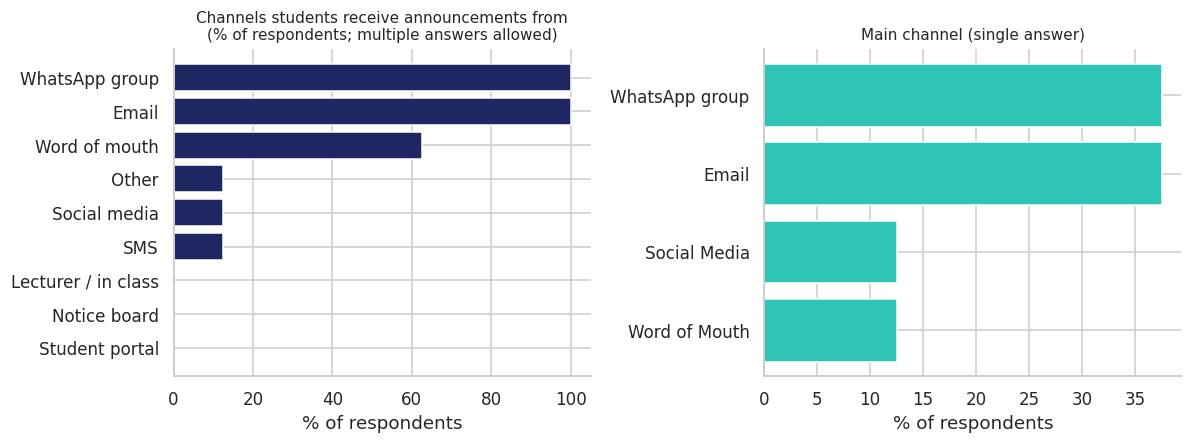

In [10]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, name), dpi=200, bbox_inches="tight")
    plt.show()


reach = (df[list(CHANNELS)].mean() * 100).rename(index=CHANNELS).sort_values()
primary = df["primary_channel"].value_counts(normalize=True).mul(100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(reach.index, reach.values, color=NAVY)
axes[0].set_title("Channels students receive announcements from\n(% of respondents; multiple answers allowed)", fontsize=10)
axes[0].set_xlabel("% of respondents")
axes[1].barh(primary.index, primary.values, color=TEAL)
axes[1].set_title("Main channel (single answer)", fontsize=10)
axes[1].set_xlabel("% of respondents")
save(fig, "01_channels.png")

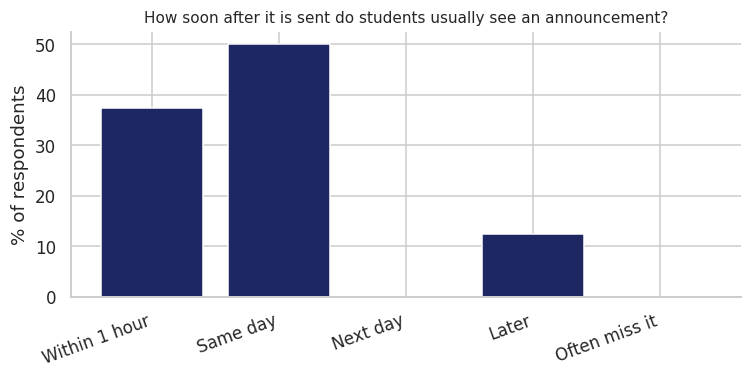

In [11]:
delay = df["seen_delay"].map(SEEN_DELAY).value_counts(normalize=True).reindex(list(SEEN_DELAY.values())).fillna(0) * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(delay.index, delay.values, color=NAVY)
ax.set_title("How soon after it is sent do students usually see an announcement?", fontsize=10)
ax.set_ylabel("% of respondents")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save(fig, "02_time_to_see.png")

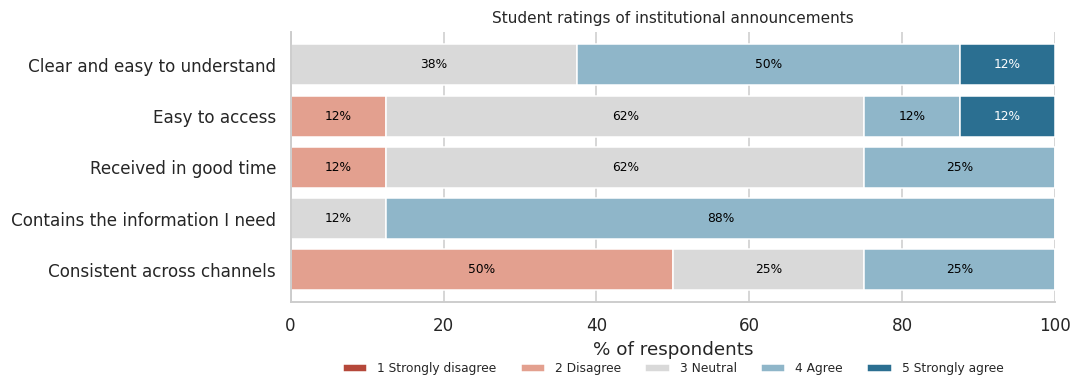

Percent agreeing (4 or 5):
Clear and easy to understand       62.5
Easy to access                     25.0
Received in good time              25.0
Contains the information I need    87.5
Consistent across channels         25.0


In [12]:
SCALE_COLOURS = ["#B5483A", "#E3A08F", "#D9D9D9", "#8FB6C9", "#2B6F91"]
SCALE_NAMES = ["1 Strongly disagree", "2 Disagree", "3 Neutral", "4 Agree", "5 Strongly agree"]

dist = pd.DataFrame({c: df[c].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0) * 100 for c in LIKERT}).T
dist.index = [LIKERT_LABELS[c] for c in dist.index]
dist.columns = SCALE_NAMES
favourable = dist.iloc[:, 3:].sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(dist))
for name, colour in zip(SCALE_NAMES, SCALE_COLOURS):
    ax.barh(dist.index, dist[name], left=left, color=colour, label=name, edgecolor="white")
    for y, (l, w) in enumerate(zip(left, dist[name])):
        if w >= 8:
            ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if colour in (SCALE_COLOURS[0], SCALE_COLOURS[4]) else "black")
    left += dist[name].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of respondents")
ax.set_title("Student ratings of institutional announcements", fontsize=10)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, frameon=False)
save(fig, "03_ratings.png")

print("Percent agreeing (4 or 5):")
print(favourable.round(1).to_string())

Cronbach's alpha for the 5-item communication index: 0.70  (≥ 0.70 is conventionally acceptable)


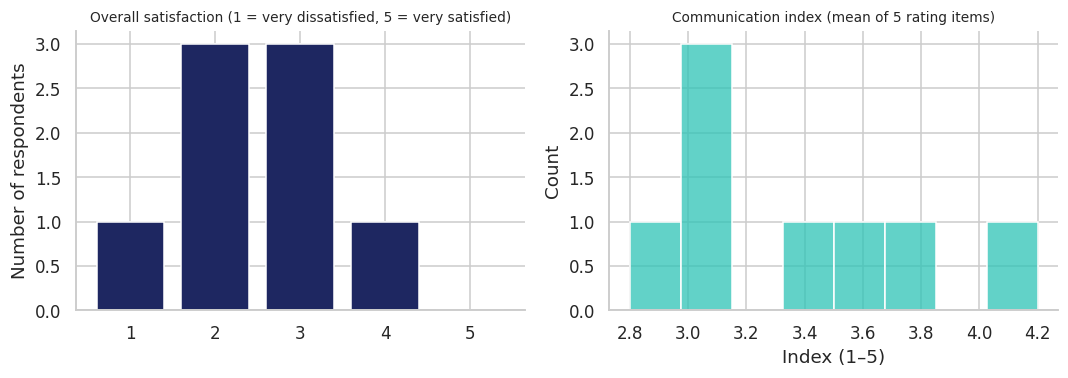

In [13]:
def cronbach_alpha(items: pd.DataFrame) -> float:
    items = items.dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))


alpha = cronbach_alpha(df[LIKERT])
print(f"Cronbach's alpha for the 5-item communication index: {alpha:.2f}  (≥ 0.70 is conventionally acceptable)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sat = df["satisfaction"].value_counts().reindex([1, 2, 3, 4, 5]).fillna(0)
axes[0].bar(sat.index.astype(int).astype(str), sat.values, color=NAVY)
axes[0].set_title("Overall satisfaction (1 = very dissatisfied, 5 = very satisfied)", fontsize=9)
axes[0].set_ylabel("Number of respondents")
sns.histplot(df["comm_index"].dropna(), bins=8, color=TEAL, ax=axes[1])
axes[1].set_title("Communication index (mean of 5 rating items)", fontsize=9)
axes[1].set_xlabel("Index (1–5)")
save(fig, "04_satisfaction.png")

Preparation      Partly adequate  n
Notice received                    
1–2 days                       1  1
3+ days                        1  1


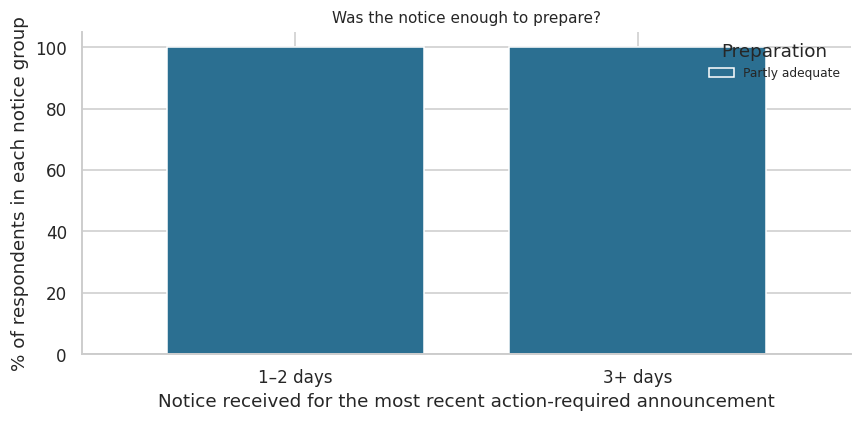

In [14]:
sub = df.dropna(subset=["notice_given", "prep_adequate"]).copy()
sub["Notice received"] = pd.Categorical(sub["notice_given"].map(NOTICE), categories=list(NOTICE.values()), ordered=True)
sub["Preparation"] = pd.Categorical(sub["prep_adequate"].map(PREP), categories=list(PREP.values()), ordered=True)
ct = pd.crosstab(sub["Notice received"], sub["Preparation"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
display_ct = ct.copy(); display_ct["n"] = ct.sum(axis=1)
print(display_ct.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ct_pct.plot(kind="bar", stacked=True, ax=ax, color=["#2B6F91", "#D9B26F", "#B5483A"], edgecolor="white", width=0.75)
ax.set_ylabel("% of respondents in each notice group")
ax.set_xlabel("Notice received for the most recent action-required announcement")
ax.set_title("Was the notice enough to prepare?", fontsize=10)
ax.legend(title="Preparation", frameon=False, fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=0)
save(fig, "05_notice_vs_preparation.png")

In [15]:
rho, p_rho = stats.spearmanr(sub["notice_hours"], sub["prep_score"])
print(f"Spearman rank correlation, notice given vs. preparation adequacy: rho = {rho:.2f}, p = {p_rho:.4f}, n = {len(sub)}")

tab = pd.crosstab(df["short_notice"], df["prep_ok"])
if tab.shape == (2, 2):
    expected = stats.contingency.expected_freq(tab)
    if expected.min() < 5:
        odds, p_assoc = stats.fisher_exact(tab)
        print(f"Fisher exact test, short notice vs. preparation OK: p = {p_assoc:.4f} (small expected counts)")
    else:
        chi2, p_assoc, _, _ = stats.chi2_contingency(tab)
        print(f"Chi-square, short notice vs. preparation OK: chi2 = {chi2:.2f}, p = {p_assoc:.4f}")
else:
    p_assoc = np.nan
    print("Not enough variation to cross-tabulate short notice against preparation.")

pct_short = df["short_notice"].mean() * 100
print(f"{pct_short:.0f}% of respondents with a recent notice received less notice than they say they need (approximate).")

Spearman rank correlation, notice given vs. preparation adequacy: rho = nan, p = nan, n = 2
Not enough variation to cross-tabulate short notice against preparation.
50% of respondents with a recent notice received less notice than they say they need (approximate).


/tmp/ipykernel_1429/2434708674.py:1: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p_rho = stats.spearmanr(sub["notice_hours"], sub["prep_score"])


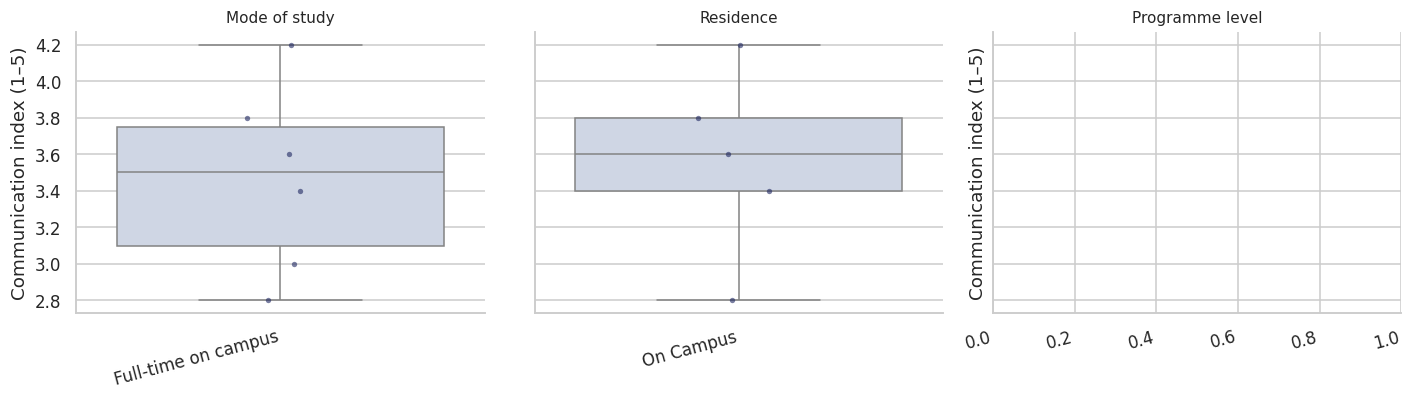

""


In [16]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (var, title) in zip(axes, [("study_mode", "Mode of study"), ("residence", "Residence"), ("programme_level", "Programme level")]):
    sizes = df[var].value_counts()
    keep = sizes[sizes >= 5].index
    data = df[df[var].isin(keep)].dropna(subset=["comm_index"])
    groups = [g["comm_index"].values for _, g in data.groupby(var)]
    if len(groups) >= 2:
        h, p = stats.kruskal(*groups)
        rows.append({"Grouping": title, "Groups compared": len(groups), "n": len(data), "H": round(h, 2), "p": round(p, 4)})
    sns.boxplot(data=data, x=var, y="comm_index", color="#CBD5E8", fliersize=0, ax=ax)
    sns.stripplot(data=data, x=var, y="comm_index", color=NAVY, size=3.5, alpha=.6, ax=ax)
    ax.set_title(title, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("Communication index (1–5)")
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
save(fig, "06_group_differences.png")
pd.DataFrame(rows)

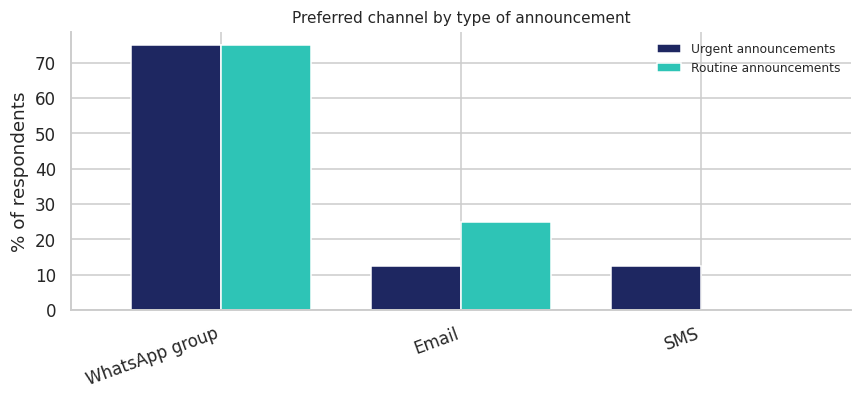

Missed or misunderstood an important announcement this semester (%):
missed_notice
Never          25.0
Once            0.0
A few times    75.0
Often           0.0


In [17]:
pref = pd.concat([
    df["pref_urgent"].value_counts(normalize=True).mul(100).rename("Urgent announcements"),
    df["pref_routine"].value_counts(normalize=True).mul(100).rename("Routine announcements"),
], axis=1).fillna(0)
pref = pref.loc[pref.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 3.8))
pref.plot(kind="bar", ax=ax, color=[NAVY, TEAL], width=0.75)
ax.set_ylabel("% of respondents"); ax.set_xlabel("")
ax.set_title("Preferred channel by type of announcement", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save(fig, "07_preferred_channels.png")

missed = df["missed_notice"].map(MISSED).value_counts(normalize=True).reindex(list(MISSED.values())).fillna(0) * 100
print("Missed or misunderstood an important announcement this semester (%):")
print(missed.round(1).to_string())

In [18]:
metrics = {
    "Valid responses (n)": n,
    "Most-used channel (any use)": reach.index[-1],
    "Main channel (most common)": primary.index[-1],
    "Seen within 1 hour (%)": round(float((df["seen_delay"] == 1).mean() * 100), 1),
    "Mean communication index (1–5)": round(float(df["comm_index"].mean()), 2),
    "Mean overall satisfaction (1–5)": round(float(df["satisfaction"].mean()), 2),
    "Index reliability (Cronbach's alpha)": round(float(alpha), 2),
    "Preparation fully adequate (%)": round(float(df["prep_ok"].mean() * 100), 1),
    "Received less notice than needed (%, approx.)": round(float(pct_short), 1),
    "Notice vs. preparation (Spearman rho)": round(float(rho), 2),
    "Missed/misunderstood an announcement at least once (%)": round(float((df["missed_notice"] > 1).mean() * 100), 1),
}
summary = pd.DataFrame({"Metric": metrics.keys(), "Value": metrics.values()})
summary.to_csv(os.path.join(OUT, "key_metrics.csv"), index=False)
df.to_csv(os.path.join(OUT, "clean_dataset.csv"), index=False)
print(f"Saved cleaned data, key metrics and charts to ./{OUT}/")
summary

Saved cleaned data, key metrics and charts to ./outputs/


,Metric,Value
0,Valid responses (n),8
1,Most-used channel (any use),WhatsApp group
2,Main channel (most common),WhatsApp group
3,Seen within 1 hour (%),37.5
4,Mean communication index (1–5),3.35
5,Mean overall satisfaction (1–5),2.5
6,Index reliability (Cronbach's alpha),0.7
7,Preparation fully adequate (%),0.0
8,"Received less notice than needed (%, approx.)",50.0
9,Notice vs. preparation (Spearman rho),NaN
